In [1]:
# Setup

from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

# To make project modules importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# dataset's path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco-churn.csv"

print(DATA_PATH)
print(DATA_PATH.exists())

/Users/priyankamanoj/UniversityCourseWork/Verizon/telco_churn_pipeline/data/raw/Telco-churn.csv
True


In [2]:
print(str(PROJECT_ROOT) in sys.path)

True


In [3]:
%reload_ext autoreload
%autoreload 2

In [4]:
%reload_ext jupyter_black

from steps.data_ingestion import load_and_split_data

from steps.preprocessing import TotalChargesCleaner, CatBoostPreprocessor

from steps.preprocessing import build_lr_preprocessor, build_tree_preprocessor

from steps.model_training import (
    build_lr_pipeline,
    build_rf_pipeline,
    build_gb_pipeline,
    build_catboost_pipeline,
    build_svm_pipeline,
    build_lr_feature_pipeline
)

from steps.evaluation import cross_validate_model, evaluate_model, plot_confusion_matrix

import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict

from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss
from sklearn.calibration import CalibratedClassifierCV
import matplotlib.pyplot as plt

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = load_and_split_data(DATA_PATH)

In [6]:
X_train.shape, X_val.shape, X_test.shape

((4930, 19), (1056, 19), (1057, 19))

In [7]:
y_train.shape, y_val.shape, y_test.shape

((4930,), (1056,), (1057,))

> Data splitting is successfully done. 

In [8]:
cleaner = TotalChargesCleaner()
X_train_clean = cleaner.fit_transform(X_train)
X_train_clean.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

In [9]:
print(X_train_clean["TotalCharges"].dtype)

float64


> The total charges column has been cleaned successfully.  
> NOTE: TotalChargesCleaner needs to run before column transformer

In [10]:
X_train_clean.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object

## Let's get the list of numerical and categorical features

In [11]:
num_features = ["tenure", "MonthlyCharges", "TotalCharges"]

In [12]:
cat_features = [col for col in X_train.columns if col not in num_features]
cat_features

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [13]:
print("Numerical:", len(num_features))
print("Categorical:", len(cat_features))

assert len(num_features) + len(cat_features) == X_train.shape[1]

Numerical: 3
Categorical: 16


# Logistic Regression 

In [14]:
# Step 1 : Initiate the preprocessor
preprocessor = build_lr_preprocessor(num_features, cat_features)

In [15]:
# Step 2 : Clean TotalCharges

X_train_clean = TotalChargesCleaner().fit_transform(X_train)

In [16]:
# Step 3: Preprocess the cleaned train set

X_train_processed = preprocessor.fit_transform(X_train_clean)

print(X_train_processed.shape)

(4930, 46)


In [17]:
# Validate the processed train set
print(X_train_clean.dtypes)

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
dtype: object


In [18]:
# build the pipeline

lr_pipeline = build_lr_pipeline(num_features, cat_features)

lr_pipeline.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [19]:
# Step 5: Let's do cross validation and check cv

lr_cv_results = cross_validate_model(lr_pipeline, X_train, y_train)

display(lr_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.809,0.668,0.560,0.608,0.845
std,0.011,0.027,0.049,0.029,0.010


In [20]:
# Step 6: Check Validation performance

lr_val_results = evaluate_model(lr_pipeline, X_val, y_val)

display(lr_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.835     0.881     0.858       776
       Churn      0.612     0.518     0.561       280

    accuracy                          0.785      1056
   macro avg      0.723     0.700     0.709      1056
weighted avg      0.776     0.785     0.779      1056



Accuracy     0.785
Precision    0.612
Recall       0.518
F1           0.561
ROC-AUC      0.842
dtype: float64

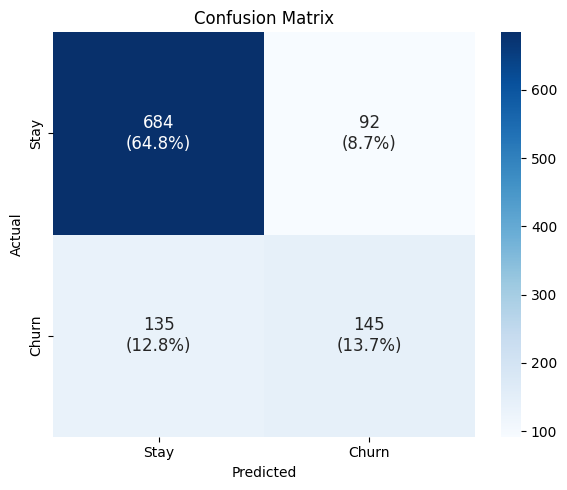

In [21]:
plot_confusion_matrix(lr_pipeline, X_val, y_val)

Metric	Score	Interpretation
---
* Accuracy	78.5%:	Correct predictions overall
* Churn precision	61.2%:	Of customers flagged as likely to churn, 61.2% actually churned
* Churn recall	51.8%:	The model identified only 51.8% of actual churners
* Churn F1	56.1%:	Balance between churn precision and recall
* Specificity	88.1%:	Correctly identified customers who stayed

Almost half the churners missed in the validation set. 

NOTES
---

I want to cast a wider net and catch the churners. But I do not want to waste resources on wrongly flagged customers. So, we shall optimise the model for Recall (the wider net) while keeping a tab on F1-score so that we precision and recall are balanced. 


> We are dealing with a moderately imbalanced dataset. Let's check if the Recall and F1-score improves with class weights. 

In [22]:
# balanced logistic regression

lr_balanced = build_lr_pipeline(num_features, cat_features, class_weight="balanced")

In [23]:
lr_balanced.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
# Let's get the cv performance

lr_balanced_cv_results = cross_validate_model(lr_balanced, X_train, y_train)
display(lr_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.748,0.516,0.806,0.629,0.845
std,0.013,0.016,0.028,0.016,0.010


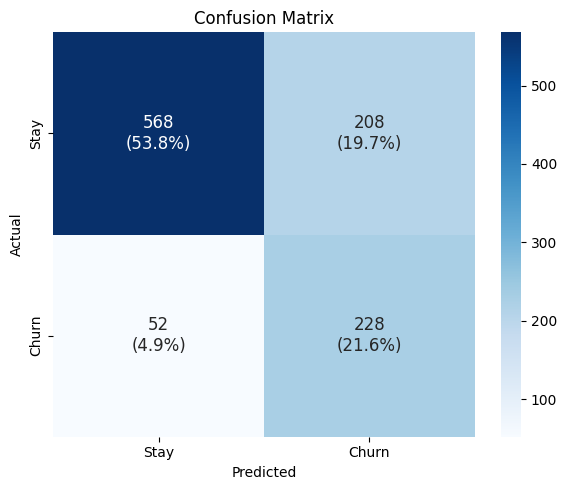

In [25]:
plot_confusion_matrix(lr_balanced, X_val, y_val)

In [26]:
lr_balanced_val_results = evaluate_model(lr_balanced, X_val, y_val)
display(lr_balanced_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.916     0.732     0.814       776
       Churn      0.523     0.814     0.637       280

    accuracy                          0.754      1056
   macro avg      0.720     0.773     0.725      1056
weighted avg      0.812     0.754     0.767      1056



Accuracy     0.754
Precision    0.523
Recall       0.814
F1           0.637
ROC-AUC      0.843
dtype: float64

NOTE
---

> After weighting the model, Recall jumped to 81%, that's an improvement of 29 points. ROC-AUC remained unchanged at 84%, which means the model can distinguish both the classes very well with or without weights. The precision has dropped 10 points, this is expected since we are optimising the model for Recall.

### RECALL : 81%, F1 : 63.8%, ROC-AUC: 0.845 shall be our baseline.

# Random Forest Classifier

In [27]:
# Let's test the model without weights

In [28]:
rf_pipeline = build_rf_pipeline(num_features, cat_features)
rf_pipeline.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [29]:
# Let's get the CV results

rf_cv_results = cross_validate_model(rf_pipeline, X_train, y_train)
display(rf_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.791,0.639,0.492,0.555,0.820
std,0.010,0.031,0.037,0.024,0.007


In [30]:
rf_val_results = evaluate_model(rf_pipeline, X_val, y_val)
display(rf_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.826     0.889     0.857       776
       Churn      0.611     0.482     0.539       280

    accuracy                          0.781      1056
   macro avg      0.719     0.686     0.698      1056
weighted avg      0.769     0.781     0.772      1056



Accuracy     0.781
Precision    0.611
Recall       0.482
F1           0.539
ROC-AUC      0.825
dtype: float64

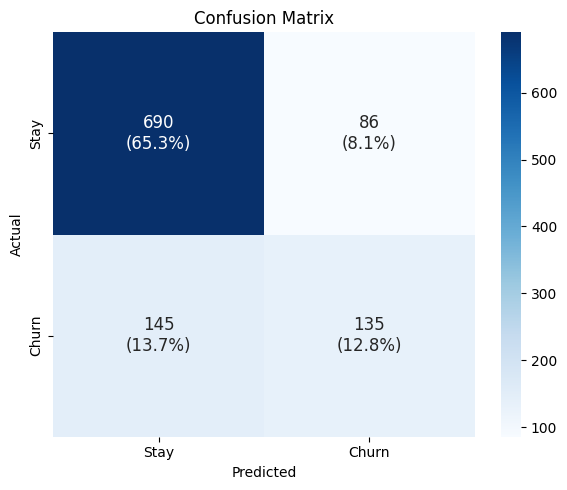

In [31]:
plot_confusion_matrix(rf_pipeline, X_val, y_val)

> With a poor recall of 47%, we need to try a weighted RF.

### Weighted RF

In [32]:
rf_balanced = build_rf_pipeline(num_features, cat_features, "balanced")

In [33]:
rf_balanced.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [34]:
# Cross validated the weighted rf model

rf_balanced_cv_results = cross_validate_model(rf_balanced, X_train, y_train)
display(rf_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.790,0.645,0.472,0.544,0.821
std,0.013,0.040,0.042,0.031,0.009


In [35]:
rf_balanced_val_perf = evaluate_model(rf_balanced, X_val, y_val)
display(rf_balanced_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.819     0.889     0.853       776
       Churn      0.598     0.457     0.518       280

    accuracy                          0.775      1056
   macro avg      0.709     0.673     0.686      1056
weighted avg      0.761     0.775     0.764      1056



Accuracy     0.775
Precision    0.598
Recall       0.457
F1           0.518
ROC-AUC      0.826
dtype: float64

> The recall for churners is at 46%. The model performance did not improve after adding class weights.


## Let's try with 'balanced_subsample' where the class_weight is computed for each tree. 

In [36]:
rf_sub = build_rf_pipeline(num_features, cat_features, "balanced_subsample")

In [37]:
rf_sub.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [38]:
# Let's get the cv scores.

rf_sub_cv_results = cross_validate_model(rf_sub, X_train, y_train)
display(rf_sub_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.794,0.652,0.484,0.555,0.819
std,0.011,0.038,0.033,0.024,0.008


In [39]:
rf_sub_val_perf = evaluate_model(rf_sub, X_val, y_val)
display(rf_sub_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.822     0.892     0.855       776
       Churn      0.607     0.464     0.526       280

    accuracy                          0.778      1056
   macro avg      0.715     0.678     0.691      1056
weighted avg      0.765     0.778     0.768      1056



Accuracy     0.778
Precision    0.607
Recall       0.464
F1           0.526
ROC-AUC      0.826
dtype: float64

Observation
---
* The recall did not improve even with class_weight as balanced_subsample where the class_weight is computed for each individual tree.
* Overall, Random Forest did not beat the baseline scores observed in Logistic Regression model. In fact, it exhibited poor performance at the default classification threshold. The model was deprioritized in favour of evaluating Gradient Boosting and CatBoost.



# Gradient Boosting

### Unweighted Gradient Boosting

In [40]:
gb_pipeline = build_gb_pipeline(num_features, cat_features)
gb_pipeline.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
# Get CV scores

gb_cv_results = cross_validate_model(gb_pipeline, X_train, y_train)
display(gb_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.795,0.644,0.515,0.571,0.835
std,0.012,0.033,0.037,0.027,0.009


* GB yielded a recall score of 51.5%. Did not beat Logistic Regression.  

In [42]:
gb_val_results = evaluate_model(gb_pipeline, X_val, y_val)
display(gb_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.824     0.885     0.853       776
       Churn      0.599     0.475     0.530       280

    accuracy                          0.777      1056
   macro avg      0.711     0.680     0.692      1056
weighted avg      0.764     0.777     0.768      1056



Accuracy     0.777
Precision    0.599
Recall       0.475
F1           0.530
ROC-AUC      0.836
dtype: float64

> GB is able to distinguish between the two classes, however it is not able to identify enough churners at a threshold of 0.5

ROC-AUC of 0.836 means that if we randomly select one churner and one non-churner, the model has approximately an 83.6% chance of assigning the churner a higher score, counting ties appropriately.

## Let's check GB balanced

In [43]:
gb_balanced = build_gb_pipeline(num_features, cat_features)

In [44]:
from sklearn.utils.class_weight import compute_sample_weight

weights = compute_sample_weight(class_weight="balanced", y=y_train)

In [45]:
gb_balanced.fit(X_train, y_train, model__sample_weight=weights)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


* Since we are using stratifiedkfold, the class distribution across the folds will represent the original dataset. So it's fine to take the weights calculated for the whole trainset and use that for CV. 

In [46]:
gb_balanced_cv = cross_validate_model(
    gb_balanced, X_train, y_train, fit_params={"model__sample_weight": weights}
)
display(gb_balanced_cv)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.756,0.529,0.731,0.613,0.833
std,0.012,0.015,0.030,0.017,0.011


* The CV recall is greater by more than 20 points. Weighting has improved the CV score. 

In [47]:
gb_balanced_val_results = evaluate_model(gb_balanced, X_val, y_val)
display(gb_balanced_val_results)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.891     0.747     0.813       776
       Churn      0.516     0.746     0.610       280

    accuracy                          0.747      1056
   macro avg      0.703     0.747     0.712      1056
weighted avg      0.792     0.747     0.759      1056



Accuracy     0.747
Precision    0.516
Recall       0.746
F1           0.610
ROC-AUC      0.835
dtype: float64

* Balanced Gradient Boosting model has improved substantially, and the CV and validation results are remarkably consistent. However, it is not better than Logistic Regression yet.

Since we have more number of categorical features than numerical features, let's try out CatBoost as it handles categorical features more elegantly. 

# CatBoost

In [48]:
cb_pipeline = build_catboost_pipeline()

cb_pipeline.fit(X_train, y_train, model__cat_features=cat_features)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False


In [49]:

# let's get the CV score for unweighted catboost

cb_cv_results = cross_validate_model(cb_pipeline, X_train, y_train,  fit_params={"model__cat_features": cat_features})
display(cb_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.804,0.663,0.538,0.592,0.843
std,0.013,0.036,0.056,0.036,0.011


In [50]:
cb_val_perf = evaluate_model(cb_pipeline, X_val, y_val)
display(cb_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.844     0.893     0.868       776
       Churn      0.647     0.543     0.590       280

    accuracy                          0.800      1056
   macro avg      0.745     0.718     0.729      1056
weighted avg      0.792     0.800     0.794      1056



Accuracy     0.800
Precision    0.647
Recall       0.543
F1           0.590
ROC-AUC      0.840
dtype: float64

> Unweighted catboost has poor recall for our objective, but the generalization is good. Let's weight it and try. 

## weighted catboost

In [51]:
cb_balanced = build_catboost_pipeline(auto_class_weights="Balanced")
cb_balanced.fit(X_train, y_train, model__cat_features = cat_features)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False


In [52]:
cb_balanced_cv_results = cross_validate_model(cb_balanced, X_train, y_train, fit_params={"model__cat_features": cat_features})
display(cb_balanced_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.765,0.542,0.757,0.631,0.842
std,0.013,0.018,0.033,0.012,0.010


* The CV score has improved by 25 points after weights. The model achieved a recall of 76% but still did not beat logistic regression recall of 82%!!


In [53]:
display(evaluate_model(cb_balanced, X_val, y_val))


Classification Report:
              precision    recall  f1-score   support

        Stay      0.890     0.750     0.814       776
       Churn      0.517     0.743     0.610       280

    accuracy                          0.748      1056
   macro avg      0.704     0.746     0.712      1056
weighted avg      0.791     0.748     0.760      1056



Accuracy     0.748
Precision    0.517
Recall       0.743
F1           0.610
ROC-AUC      0.837
dtype: float64

> Weighted Gradient Boosting and Weighted cat boost performs very similarly. Although, the weighted Logistic Regression still remains to be the better performer. 

# Support Vector Machines

In [54]:
svm_linear = build_svm_pipeline(num_features, cat_features)
svm_linear.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [55]:
svm_linear_cv = cross_validate_model(svm_linear, X_train, y_train)
display(svm_linear_cv)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.805,0.659,0.552,0.600,0.837
std,0.009,0.022,0.044,0.026,0.011


In [56]:
svm_linear_val_perf = evaluate_model(svm_linear, X_val, y_val)
display(svm_linear_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.843     0.885     0.864       776
       Churn      0.631     0.543     0.583       280

    accuracy                          0.795      1056
   macro avg      0.737     0.714     0.724      1056
weighted avg      0.787     0.795     0.789      1056



Accuracy     0.795
Precision    0.631
Recall       0.543
F1           0.583
ROC-AUC      0.838
dtype: float64

* The recall is poor for our objective, but the model is generalising well. Let's try weighting it 

In [57]:
svm_linear_balanced = build_svm_pipeline(
    num_features,
    cat_features,
    kernel="linear",
    class_weight="balanced"
)

svm_linear_balanced_cv = cross_validate_model(
    svm_linear_balanced,
    X_train,
    y_train
)

display(svm_linear_balanced_cv)

svm_linear_balanced.fit(X_train, y_train)

display(
    evaluate_model(svm_linear_balanced, X_val, y_val)
)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.714,0.479,0.814,0.602,0.840
std,0.022,0.022,0.020,0.014,0.009



Classification Report:
              precision    recall  f1-score   support

        Stay      0.920     0.655     0.765       776
       Churn      0.468     0.843     0.602       280

    accuracy                          0.705      1056
   macro avg      0.694     0.749     0.684      1056
weighted avg      0.800     0.705     0.722      1056



Accuracy     0.705
Precision    0.468
Recall       0.843
F1           0.602
ROC-AUC      0.840
dtype: float64

## Let's try unweighted RBF SVM

In [58]:
svm_rbf = build_svm_pipeline(
    num_features,
    cat_features,
    kernel="rbf",
    class_weight=None
)

svm_rbf_cv = cross_validate_model(
    svm_rbf, X_train, y_train
)

display(svm_rbf_cv)

svm_rbf.fit(X_train, y_train)

display(evaluate_model(svm_rbf, X_val, y_val))

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.80,0.667,0.495,0.568,0.80
std,0.01,0.026,0.034,0.026,0.02



Classification Report:
              precision    recall  f1-score   support

        Stay      0.829     0.898     0.862       776
       Churn      0.633     0.486     0.549       280

    accuracy                          0.789      1056
   macro avg      0.731     0.692     0.706      1056
weighted avg      0.777     0.789     0.779      1056



Accuracy     0.789
Precision    0.633
Recall       0.486
F1           0.549
ROC-AUC      0.784
dtype: float64

* Generalises well but poor recall. 

## Weighted rbf

In [59]:
svm_rbf_balanced = build_svm_pipeline(
    num_features,
    cat_features,
    kernel="rbf",
    class_weight= "balanced"
)

svm_rbf_cv_balanced = cross_validate_model(
    svm_rbf, X_train, y_train
)

display(svm_rbf_cv_balanced)

svm_rbf_balanced.fit(X_train, y_train)

display(evaluate_model(svm_rbf, X_val, y_val))

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.80,0.667,0.495,0.568,0.80
std,0.01,0.026,0.034,0.026,0.02



Classification Report:
              precision    recall  f1-score   support

        Stay      0.829     0.898     0.862       776
       Churn      0.633     0.486     0.549       280

    accuracy                          0.789      1056
   macro avg      0.731     0.692     0.706      1056
weighted avg      0.777     0.789     0.779      1056



Accuracy     0.789
Precision    0.633
Recall       0.486
F1           0.549
ROC-AUC      0.784
dtype: float64

* RBF performed poorly compared to weighted linear SVM. This means that the patterns are captured decently by a linear decision boundary. 

## Take-away

The ensemble methods did not demonstrate an improvement in performance for the complexity it added. This suggests that a simple linear model may adequately capture much of the signal available in the data. Do note that Ensemble methods produced a comparable ROC - AUC score, but at their default classification - the recall was simply poor. Additional tuning may alter these results. 

But- simple, decently performing, interpretable model is the best model in this case as the alternatives didn't justify the complexity it added.. Therefore, we shall tune the Log Reg model to see if the recall and F1 can be bumped up meaningfully. 

# Hyperparamter tuning with Optuna

In [60]:
from sklearn.metrics import make_scorer, fbeta_score

f2_scorer = make_scorer(fbeta_score, beta=2)

In [61]:
def objective(trial):

    C = trial.suggest_float("C", 0.001, 100, log=True)
    penalty = trial.suggest_categorical("penalty", ["l1", "l2"])
    class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])

    model = build_lr_pipeline(
        num_features,
        cat_features,
        C = C,
        penalty = penalty,
        class_weight = class_weight,
        solver = "saga"
    )

    cv = StratifiedKFold(
        n_splits = 5,
        shuffle = True,
        random_state = 42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv = cv,
        scoring= f2_scorer # recall gets 4x weight of precision
    )

    return scores.mean()

In [62]:
%%time
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(objective, n_trials=25)

print("Best CV F2:", round(study.best_value, 3))
print("Best parameters:", study.best_params)

Best CV F2: 0.725
Best parameters: {'C': 14.018518137181351, 'penalty': 'l1', 'class_weight': 'balanced'}
CPU times: user 1min 3s, sys: 204 ms, total: 1min 3s
Wall time: 1min 3s


In [63]:
best_lr = build_lr_pipeline(
    num_features,
    cat_features,
    C=study.best_params["C"],
    penalty=study.best_params["penalty"],
    class_weight=study.best_params["class_weight"],
    solver="saga"
)

In [64]:
best_lr.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [65]:
display(evaluate_model(best_lr, X_val, y_val))


Classification Report:
              precision    recall  f1-score   support

        Stay      0.915     0.736     0.816       776
       Churn      0.525     0.811     0.638       280

    accuracy                          0.756      1056
   macro avg      0.720     0.773     0.727      1056
weighted avg      0.812     0.756     0.768      1056



Accuracy     0.756
Precision    0.525
Recall       0.811
F1           0.638
ROC-AUC      0.843
dtype: float64

* Optuna has barely changed our Logistic Regression's performance.
* Logistic Regression is already capturing a substantial amount of the available predictive signal, and adjusting its regularization isn't producing meaningful improvements.

> Let's move to decision threshold tuning

# Decision threshold tuning 

In [66]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# One estimated churn probabilty for a training observation, generated without training on that observation
oof_probs = cross_val_predict(
    best_lr,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

In [67]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [68]:

threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.01):

    y_pred = (oof_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_train, y_pred, zero_division=0),
        "recall": recall_score(y_train, y_pred, zero_division=0),
        "f1": f1_score(y_train, y_pred, zero_division=0),
        "f2": fbeta_score(y_train, y_pred, beta=2, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(["precision"], ascending=False).tail(20)

,threshold,precision,recall,f1,f2
19,0.39,0.458984,0.876911,0.602574,0.741819
18,0.38,0.454867,0.886086,0.601141,0.744859
17,0.37,0.453204,0.892202,0.601082,0.747406
16,0.36,0.448355,0.896024,0.597654,0.746877
15,0.35,0.442895,0.898318,0.593285,0.745086
14,0.34,0.438662,0.902141,0.590295,0.744761
13,0.33,0.433589,0.905963,0.586488,0.743879
12,0.32,0.430841,0.912080,0.585234,0.745532
11,0.31,0.427451,0.916667,0.583029,0.745925
10,0.30,0.425449,0.922783,0.582388,0.747924


In [69]:
chosen_threshold = 0.37

val_probs = best_lr.predict_proba(X_val)[:, 1]
val_pred = (val_probs >= chosen_threshold).astype(int)

print(classification_report(
    y_val,
    val_pred,
    target_names=["Stay", "Churn"],
    digits=3
))

print(
    "Validation F2:",
    round(fbeta_score(y_val, val_pred, beta=2), 3)
)

              precision    recall  f1-score   support

        Stay      0.953     0.595     0.733       776
       Churn      0.450     0.918     0.604       280

    accuracy                          0.681      1056
   macro avg      0.701     0.757     0.668      1056
weighted avg      0.819     0.681     0.699      1056

Validation F2: 0.76


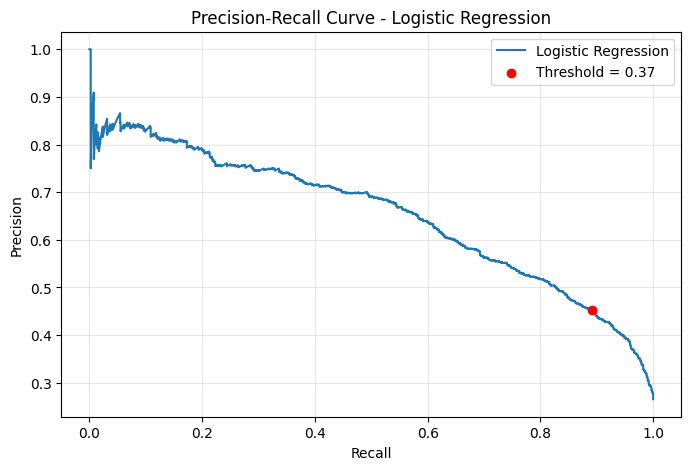

In [70]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_train, oof_probs
)

plt.figure(figsize=(8, 5))

plt.plot(recall, precision, label="Logistic Regression")

plt.scatter(
    threshold_df.loc[threshold_df["threshold"] == 0.37, "recall"],
    threshold_df.loc[threshold_df["threshold"] == 0.37, "precision"],
    label="Threshold = 0.37",
    color="red",
    zorder=5
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

* If we try to pick a threshold that gives good recall, then we are at the risk of false positives. It is observed that, at a decision threshold of 0.37 - the recall is 91.8% and precision is 45%. At this precision, if the model flags 100 customers as churners, then only 45 are correct (match the reality). This means, the model flagged 55 customers as churners incorrectly. Instead of trying to get one best threshold, let's perform **Risk Stratification** so that, we can divide the flagged customers into segments of high to low risk based on which the retention efforts can be decided. 

# Feature Engineering to check if LR performance improves

we shall introduce tenure x monthly charges for interactions and tenure squared (non-linear term)

In [71]:
lr_features = build_lr_feature_pipeline(num_features, cat_features, "balanced")

In [72]:
# Cross validate

lr_features_cv_results = cross_validate_model(lr_features, X_train, y_train)
display(lr_features_cv_results)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
mean,0.749,0.518,0.791,0.626,0.846
std,0.013,0.016,0.025,0.016,0.009


In [73]:
# Validation performance

lr_features.fit(X_train, y_train)
lr_feature_val_perf = evaluate_model(lr_features, X_val, y_val)
display(lr_feature_val_perf)


Classification Report:
              precision    recall  f1-score   support

        Stay      0.909     0.732     0.811       776
       Churn      0.517     0.796     0.627       280

    accuracy                          0.749      1056
   macro avg      0.713     0.764     0.719      1056
weighted avg      0.805     0.749     0.762      1056



Accuracy     0.749
Precision    0.517
Recall       0.796
F1           0.627
ROC-AUC      0.847
dtype: float64

> engineered features may have helped the model rank customers slightly better, but they haven't improved our preferred classification metrics.
> Note that the feature engineered model used same config as the balanced log reg model.


### The current flow goes on like this:

1. Validated weighted and unweighted models: weighted models showed significant improvement in performance.
2. We tried Hyperparameter tuning with optuna and learned that the default configuration was already at its best. The tuned parameters improved the performance barely.
3. Since the performance observed was at the default threshold, we tried tuning the threshold in hopes of seeing better performance. While the threshold of 0.37 yields a promising recall, reducing the threshold hurt precision too much. Tuning for a single best threshold was observed to be inadequate. Risk Stratification could be an operationally better approach.
4. As a last attempt, feature engineered the model at default settings and balancing the class weights, introducing an interaction term(tenure x monthly charges) and a non linear term (tenure squared). The model performed slightly worse. It was learnt that engineered features did not demonstrate sufficient improvement in the performance. 

# Retention Strategy using Model's Churn scores

We shall do so, by trying to answer these questions.

1. Caliberation : Can we trust the predicted probabilities?
2. Risk Stratification: How should we group customers based on risk tiers using risk rankings ?
3. Operational Strategy: Which interventions are appropriate for each tier, considering cost and bandwidth ? 

## Caliberation Curve

In [74]:
lr_final = build_lr_pipeline(num_features, cat_features, class_weight = "balanced")
display(lr_final)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [75]:
lr_final.fit(X_train, y_train)

,steps,"[('cleaner', ...), ('preprocessor', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


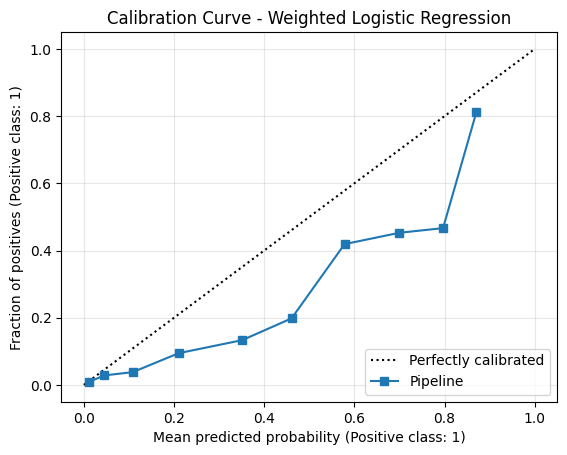

Brier score: 0.167


In [76]:
CalibrationDisplay.from_estimator(
    lr_final,
    X_val,
    y_val,
    n_bins=10,
    strategy="quantile"
)

plt.title("Calibration Curve - Weighted Logistic Regression")
plt.grid(alpha=0.3)
plt.show()

val_probs = lr_final.predict_proba(X_val)[:, 1]

print(
    "Brier score:",
    round(brier_score_loss(y_val, val_probs), 4)
)

* The weighted Logistic Regression model is overestimating the churn probabilities. Predicted probability is higher than the observed churn frequency (the blue line -observed reality is below the dotted line -theoritical ideal y=x). Think of it like a thermometer which reads hotter than the actual temperature.
* This could be possible because we weighted the classes.
* So, our model's churn probability should be be interpreted literally indicating that we need to caliberate the model - try to bring the blue line closer to the dotted line.

# Caliberating the model

* The churn probabilities produced by our model is exaggerating the risk of churn. We shall use caliberator as a translator, that tones down the probability to make it more realistic.
* We shall use try out two methods and pick the one that performs well.
  1. Sigmoid Platt - Learns smooth logistic mapping from scores to probabilities
  2. Isotonic - Learns a flexible monotonic mapping

In [77]:
# 1. Sigmoid Platt

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state=42
)

lr_calibrated = CalibratedClassifierCV(
    lr_final,
    method = 'sigmoid',
    cv = cv,
    ensemble = False 
)
"""
ensemble = False does the following:

1. Generates out-of-fold predictions on the training data.
2. Uses those predictions and actual outcomes to learn a calibration mapping.
3. Fits the underlying Logistic Regression pipeline on the full training set.
4. Applies the learned calibration mapping to its scores.

"""

'\nensemble = False does the following:\n\n1. Generates out-of-fold predictions on the training data.\n2. Uses those predictions and actual outcomes to learn a calibration mapping.\n3. Fits the underlying Logistic Regression pipeline on the full training set.\n4. Applies the learned calibration mapping to its scores.\n\n'

In [78]:
lr_calibrated.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,method,'sigmoid'
,cv,StratifiedKFo... shuffle=True)
,n_jobs,None
,ensemble,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


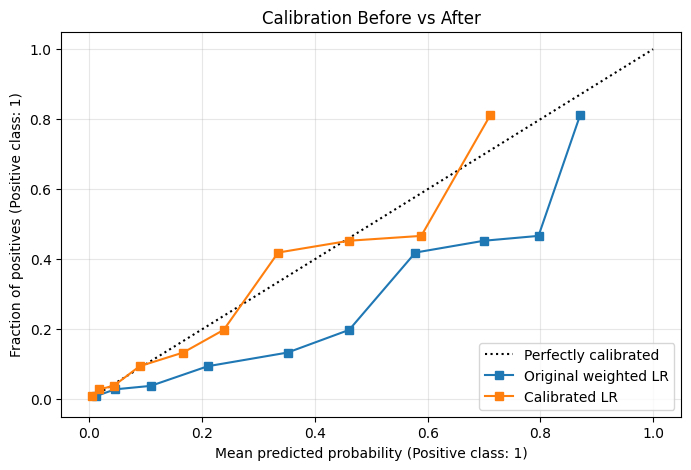

In [79]:
fig, ax = plt.subplots(figsize=(8, 5))

CalibrationDisplay.from_estimator(
    lr_final,
    X_val,
    y_val,
    n_bins=10,
    strategy="quantile",
    name="Original weighted LR",
    ax=ax
)

CalibrationDisplay.from_estimator(
    lr_calibrated,
    X_val,
    y_val,
    n_bins=10,
    strategy="quantile",
    name="Calibrated LR",
    ax=ax
)

plt.title("Calibration Before vs After")
plt.grid(alpha=0.3)
plt.show()

In [80]:
original_probs = lr_final.predict_proba(X_val)[:, 1]
calibrated_probs = lr_calibrated.predict_proba(X_val)[:, 1]

print(
    "Original Brier:",
    round(brier_score_loss(y_val, original_probs), 4)
)

print(
    "Calibrated Brier:",
    round(brier_score_loss(y_val, calibrated_probs), 4)
)

Original Brier: 0.167
Calibrated Brier: 0.1369


In [81]:
(brier_score_loss(y_val, calibrated_probs) - brier_score_loss(y_val, original_probs))/brier_score_loss(y_val, original_probs)

-0.18066457159580354

NOTES
---
* We have achieved an decent reduction(18%) in the Brier score indicating substantial improvement. However, the calibrated curved fluctuates especially in the middle. 

In [82]:
# Isotonic Calibration
lr_isotonic = CalibratedClassifierCV(
    estimator=lr_final,
    method="isotonic",
    cv=cv,
    ensemble=False
)

lr_isotonic.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,method,'isotonic'
,cv,StratifiedKFo... shuffle=True)
,n_jobs,None
,ensemble,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


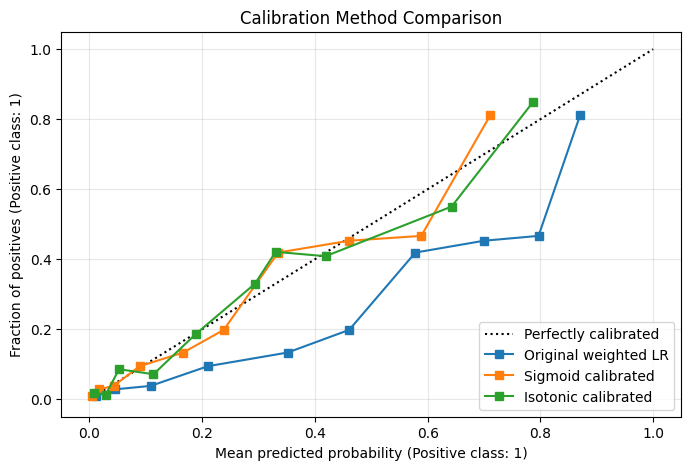

Original weighted LR: 0.1670
Sigmoid calibrated: 0.1369
Isotonic calibrated: 0.1372


In [83]:
fig, ax = plt.subplots(figsize=(8, 5))

models = {
    "Original weighted LR": lr_final,
    "Sigmoid calibrated": lr_calibrated,
    "Isotonic calibrated": lr_isotonic
}

for name, model in models.items():
    CalibrationDisplay.from_estimator(
        model,
        X_val,
        y_val,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax
    )

plt.title("Calibration Method Comparison")
plt.grid(alpha=0.3)
plt.show()

for name, model in models.items():
    probs = model.predict_proba(X_val)[:, 1]
    score = brier_score_loss(y_val, probs)
    print(f"{name}: {score:.4f}")

Observation
---
* Owing to the slightly better Brier score and simpler transformation, we will use the model that's calibrated with sigmoid method.

In [84]:
import sys
print(sys.executable)

/opt/anaconda3/bin/python
